# Dolomite change: data analysis

The short film *Dolomite change. Un viaggio in montagna attraverso vent'anni di cambiamenti*, by Marco Frilli and Giacomo Roversi (2026), follows two hikers who return to the Dolomites above Cortina d'Ampezzo twenty years after a trek in July 2005. This notebook contains the data analysis behind the film: a day-by-day reconstruction of the weather during the 2005 trek, and the summer climate of the area since 1950, from the freezing level and snowfall in the ERA5 reanalysis and from the temperature trends of the ARPAV weather stations in Veneto.

Run it from the repository root, in the environment described in the README. Figures taken from the film's animations keep their Italian labels.

In [1]:
import csv
import io
import json
import statistics
import sys
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display

RADICE = Path.cwd()
sys.path.insert(0, str(RADICE / "scripts"))
from anim_stile import COL, carica_font  # film palette and font  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402

carica_font()
RIS = RADICE / "data" / "risultati"
QUOTE = {"Passo Falzarego": 2105, "Rifugio Giussani": 2580,
         "Rifugio Lagazuoi": 2752, "Tofana di Rozes": 3225}


def leggi(nome: str) -> list[dict]:
    return list(csv.DictReader((RIS / nome).open(encoding="utf8")))


def ols(xs, ys):
    """Linear regression: (slope, standard error, t), as in the scripts."""
    n = len(xs)
    mx, my = statistics.fmean(xs), statistics.fmean(ys)
    sxx = sum((x - mx) ** 2 for x in xs)
    b = sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / sxx
    a = my - b * mx
    se = (sum((y - a - b * x) ** 2 for x, y in zip(xs, ys)) / (n - 2) / sxx) ** 0.5
    return b, se, b / se


def media(anni, vals, lo, hi):
    return statistics.fmean(v for a, v in zip(anni, vals) if lo <= a <= hi)


def tabella(intestazione, righe):
    testa = "| " + " | ".join(intestazione) + " |\n|" + "---|" * len(intestazione)
    corpo = "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in righe)
    display(Markdown(testa + "\n" + corpo))


def mostra(fig, dpi=60):
    """Show the figure as a PNG, smaller than the video frame."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=fig.get_facecolor())
    plt.close(fig)
    display(Image(buf.getvalue()))


def scuro(figsize=(16, 6.5)):
    """Figure and axes in the film's dark palette."""
    fig, ax = plt.subplots(figsize=figsize, dpi=100, facecolor=COL["fondo"])
    ax.set_facecolor(COL["fondo"])
    for lato in ("top", "right"):
        ax.spines[lato].set_visible(False)
    for lato in ("left", "bottom"):
        ax.spines[lato].set_color(COL["asse"])
    ax.tick_params(colors=COL["muto"], labelsize=13)
    return fig, ax

## Summary

The cold spell of 5-8 July 2005 was exceptional even at the time: July 2005 is the sixth snowiest July since 1950. A snowy week in 2005 against a warm day in 2025 is not evidence of climate change. The summer record since 1950 shows the change: at **Passo Falzarego** (2105 m), the summer days on which snow could fall went from about six per summer in the 1960s-1980s to one day in the last six years.

## 1. The 2005 trek: itinerary and weather

Itinerary: departure on Sunday 3 July, six nights (two at Rifugio Scoiattoli, two at Rifugio Lagazuoi, two at Rifugio Giussani), descent to Cortina on 9 July. Daily ERA5 data (Copernicus/ECMWF) via Open-Meteo, with temperature adjusted to the altitude of each day's location (`python scripts/diario_2005.py`).

| day | date | route | altitude | T max | T min | precip. | snow |
|---|---|---|---:|---:|---:|---:|---:|
| 1 | 3 Jul | Bai de Dones → Rif. Scoiattoli | 2255 m | +17.3 °C | +3.1 °C | 0.1 mm | 0 |
| 2 | 4 Jul | Averau, back to Rif. Scoiattoli | 2255 m | +15.5 °C | +7.8 °C | 6.9 mm | 0 |
| 3 | 5 Jul | Rif. Scoiattoli → Passo Falzarego → Rif. Lagazuoi | 2752 m | +4.2 °C | −4.2 °C | 37.2 mm | 3.3 cm |
| 4 | 6 Jul | Lagazuoi, Kaiserjäger route and war tunnels | 2752 m | +10.4 °C | −4.7 °C | 4.2 mm | 0 |
| 5 | 7 Jul | Rif. Lagazuoi → Rif. Giussani | 2580 m | +5.7 °C | +0.4 °C | 23.4 mm | 0 |
| 6 | 8 Jul | Rif. Giussani, Tofana climb cancelled | 2580 m | +8.2 °C | −3.5 °C | 22.9 mm | 3.9 cm |
| 7 | 9 Jul | descent to Cortina | 1224 m | +15.4 °C | +8.4 °C | 8.9 mm | 0 |

Week total: 7.2 cm of snow and three nights below 0 °C.

### 1a. Passo Falzarego (2105 m): daily ERA5 series

The series stored in the repository, 3-9 July 2005:

In [2]:
d = json.load((RADICE / "data/openmeteo/Passo_Falzarego_era5_2005-2005.json").open())["daily"]
righe = []
for i, t in enumerate(d["time"]):
    if "2005-07-03" <= t <= "2005-07-09":
        righe.append((f"{int(t[8:10])} Jul", f"{d['temperature_2m_max'][i]:+.1f}",
                      f"{d['temperature_2m_min'][i]:+.1f}", f"{d['precipitation_sum'][i]:.1f}",
                      f"{d['snowfall_sum'][i]:.1f}"))
tabella(["date", "T max °C", "T min °C", "precip. mm", "snow cm"], righe)

| date | T max °C | T min °C | precip. mm | snow cm |
|---|---|---|---|---|
| 3 Jul | +18.3 | +4.1 | 0.1 | 0.0 |
| 4 Jul | +16.5 | +8.7 | 6.9 | 0.0 |
| 5 Jul | +8.4 | +0.0 | 37.2 | 3.3 |
| 6 Jul | +14.6 | -0.5 | 4.2 | 0.0 |
| 7 Jul | +8.7 | +3.5 | 23.4 | 0.0 |
| 8 Jul | +11.3 | -0.5 | 22.9 | 3.9 |
| 9 Jul | +10.5 | +3.2 | 11.5 | 0.0 |

### 1b. Rifugio Lagazuoi: ice on the evening of 5 July

Hourly ERA5 data at 2752 m, local time:

| hour | air T | soil T 0-7 cm | dew point | notes |
|---|---:|---:|---:|---|
| 00-11 | +4.5 → +2.0 | about +5 | ≈ air T | continuous rain, about 24 mm |
| 12 | −1.7 | +4.0 | −1.9 | below 0 °C, snow begins |
| 14 | −4.2 | +2.9 | −4.3 | snow, afternoon minimum |
| 17-19 | +0.6 → +2.7 | +2.4 | −2.2 → −3.0 | above 0 °C again, surfaces still wet |
| 22 | −0.8 | +0.8 | −4.4 | air below 0 °C again |
| 23 | −2.1 | −0.1 | −4.9 | ground freezes |
| night | down to −4.7 | down to −3.2 | about −5 | |

After a morning of rain, dry post-frontal air arrived in the evening (dew point −4.4 °C at 22:00), and between 22:00 and 23:00 the air and the ground fell below 0 °C, freezing the water left on the surfaces. Reproducible with:

```bash
python scripts/diario_2005.py --ore 2005-07-05
```

### 1c. Freezing level and snow level

Freezing level from the ERA5 pressure levels, hourly. The snow level is taken as 300 m below the freezing level, the distance falling snowflakes need to melt; with heavy precipitation it can be lower. Estimated snow level hour by hour for the week:

| local time | freezing level | estimated snow level |
|---|---|---|
| 5 Jul 02:00 | 3775 m | 3475 m |
| 5 Jul 11:00 | 3418 m | 3118 m |
| 5 Jul 12:00 | 2927 m | 2627 m |
| 5 Jul 13:00 | 2717 m | 2417 m |
| 5 Jul 17:00 | 2713 m | 2413 m |
| 6 Jul 00:00 | 2644 m | 2344 m |

8 July: freezing level between 2602 and 2929 m, lowest at 06:00
8 July: snow level below Rifugio Giussani (2580 m) at hours 00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13, 14, 21
5 July: freezing level below the Tofana summit from 12:00 to 23:00 (12 of 24 hours)
8 July: freezing level below the Tofana summit from 00:00 to 23:00 (24 of 24 hours)


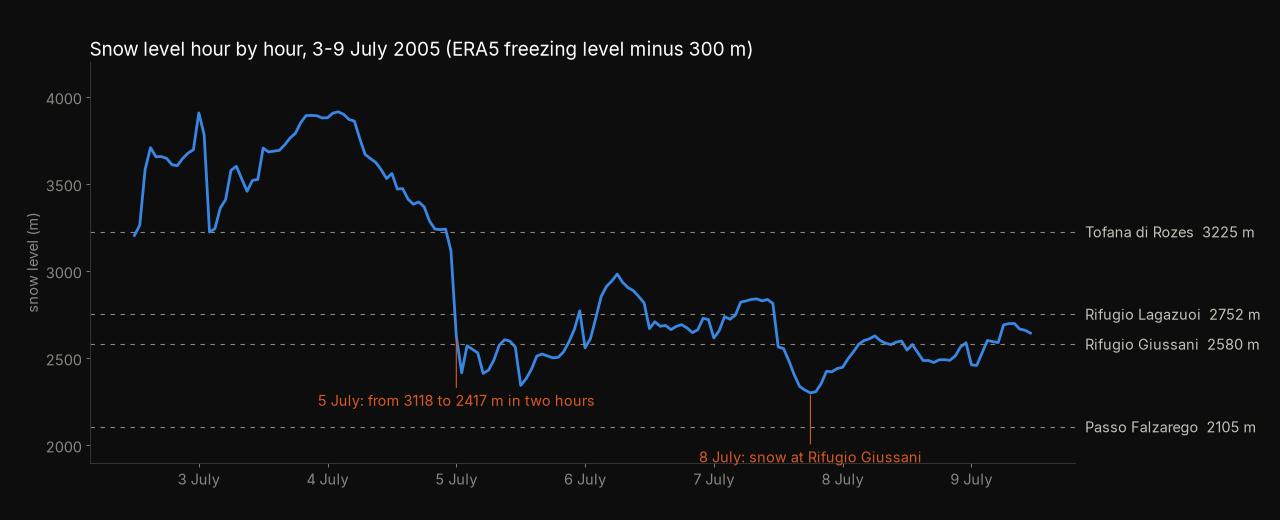

In [3]:
from zero_termico import carica, quota_zero

z = quota_zero(carica("_lug2005_orario.nc")).sel(time=slice("2005-07-02T22", "2005-07-09T21"))
locale = z["time"].values + np.timedelta64(2, "h")      # CEST = UTC + 2
zt = z.values
neve = zt - 300
ora = lambda t: str(t)[:13]

chiave = ["2005-07-05T02", "2005-07-05T11", "2005-07-05T12", "2005-07-05T13",
          "2005-07-05T17", "2005-07-06T00"]
tabella(["local time", "freezing level", "estimated snow level"],
        [(f"{int(ora(t)[8:10])} Jul {ora(t)[11:13]}:00", f"{q:.0f} m", f"{n:.0f} m")
         for t, q, n in zip(locale, zt, neve) if ora(t) in chiave])

g8 = [(ora(t)[11:13], q, n) for t, q, n in zip(locale, zt, neve) if ora(t)[:10] == "2005-07-08"]
sotto = [h for h, q, n in g8 if n < QUOTE["Rifugio Giussani"]]
print(f"8 July: freezing level between {min(q for _, q, _ in g8):.0f} and {max(q for _, q, _ in g8):.0f} m,"
      f" lowest at {min(g8, key=lambda x: x[1])[0]}:00")
print(f"8 July: snow level below Rifugio Giussani (2580 m) at hours {', '.join(sotto)}")
for giorno in ("2005-07-05", "2005-07-08"):
    sopra = [ora(t)[11:13] for t, q in zip(locale, zt) if ora(t)[:10] == giorno and q < QUOTE["Tofana di Rozes"]]
    print(f"{int(giorno[8:10])} July: freezing level below the Tofana summit from {sopra[0]}:00 to {sopra[-1]}:00"
          f" ({len(sopra)} of 24 hours)")

fig, ax = scuro()
fig.subplots_adjust(left=0.07, right=0.84)
ax.plot(locale, neve, color=COL["serie"], lw=2.5)
for nome, q in QUOTE.items():
    ax.axhline(q, color=COL["muto"], lw=1, ls=(0, (4, 5)))
    ax.text(1.01, q, f"{nome}  {q} m", color=COL["testo2"], fontsize=13, va="center",
            transform=ax.get_yaxis_transform())
for istante, etichetta in (("2005-07-05T12", "5 July: from 3118 to 2417 m in two hours"),
                           ("2005-07-08T06", "8 July: snow at Rifugio Giussani")):
    i = [k for k, t in enumerate(locale) if ora(t) == istante][0]
    ax.annotate(etichetta, (locale[i], neve[i]), xytext=(0, -50), textcoords="offset points",
                color=COL["clou"], fontsize=13, ha="center", va="top",
                arrowprops=dict(arrowstyle="-", color=COL["clou"], lw=1))
giorni = [np.datetime64(f"2005-07-0{g}T12") for g in range(3, 10)]
ax.set_xticks(giorni, [f"{g} July" for g in range(3, 10)])
ax.set_ylim(1900, 4200)
ax.set_ylabel("snow level (m)", color=COL["muto"], fontsize=13)
ax.set_title("Snow level hour by hour, 3-9 July 2005 (ERA5 freezing level minus 300 m)",
             color=COL["testo"], fontsize=17, loc="left")
mostra(fig, dpi=80)

From the authors' account of 5 July: *"al Passo Falzarego eravamo completamente fradici, e mentre salivamo verso il Lagazuoi iniziò a nevicare"* (at Passo Falzarego we were soaked, and while climbing towards Lagazuoi it started to snow). With the snow level between 2400 and 2600 m, it rained at the pass (2105 m) and snowed higher up, on the way to the hut (2752 m). On 8 July the snow level stayed below Rifugio Giussani (2580 m) from midnight to 14:00.

```bash
python scripts/zero_termico.py --pattern "_lug2005_orario.nc" \
    --giorni 2005-07-05 2005-07-08
```

## 2. How unusual was that week?

Monthly means observed at the ARPAV station of Passo Falzarego (2090 m), 1994-2024:

| | value | rank in 31 years |
|---|---:|---|
| July 2005, mean T | 10.3 °C | 8th coldest |
| July 2005, precipitation | 192.4 mm | 6th wettest |
| August 2005, mean T | 8.4 °C | 2nd coldest, −2.6 °C (z = −1.6) |
| August 2006, mean T | 6.7 °C | coldest, −4.3 °C (z = −2.6) |
| August 2024, mean T | 14.1 °C | warmest |

On the ERA5 record 1950-2025, for the grid cell over the area:

In [4]:
r = leggi("neve_estiva_Passo_Falzarego.csv")
t_jja = {int(x["anno"]): float(x["t_media_jja"]) for x in r}
neve_lug = {int(x["anno"]): int(x["neve_gg_lug"]) for x in r}
rango = lambda serie, anno: sorted(serie.values()).index(serie[anno]) + 1   # 1 = lowest
print(f"summer 2005, mean T: rank {rango(t_jja, 2005)} of {len(t_jja)} (1 = coldest)")
print(f"July 2005, snow days: {neve_lug[2005]}, rank {rango(neve_lug, 2005)} of {len(neve_lug)}"
      f" (1 = least snowy)")
print(f"Julys with at least 2 snow days: {sum(v >= 2 for v in neve_lug.values())} of {len(neve_lug)};"
      f" with more than 2: {sum(v > 2 for v in neve_lug.values())}")

summer 2005, mean T: rank 47 of 76 (1 = coldest)
July 2005, snow days: 2, rank 68 of 76 (1 = least snowy)
Julys with at least 2 snow days: 9 of 76; with more than 2: 5


Summer 2005 as a whole ranks 47th of 76 for mean temperature, slightly above the median: it was not a cold summer. July 2005, with 2 snow days, ranks 68th of 76: only five Julys had more snow days.

## 3. Summer trends from ERA5, 1950-2025

ERA5 grid cell (about 31 km) over the area, June-August indices:

In [5]:
r = leggi("neve_estiva_Passo_Falzarego.csv")
anni = [int(x["anno"]) for x in r]
indici = [("mean summer T", "t_media_jja", "°C", 1), ("frost days (Tmin ≤ 0)", "gelo_gg_jja", "days", 1),
          ("snow days Jun-Aug", "neve_gg_jja", "days", 1), ("snow days in July", "neve_gg_lug", "days", 1),
          ("total summer snow", "neve_cm_jja", "cm", 1)]
righe = []
for nome, col, u, dec in indici:
    v = [float(x[col]) for x in r]
    b, se, t = ols(anni, v)
    righe.append((nome, f"{media(anni, v, 1980, 1989):.1f}", f"{media(anni, v, 2020, 2025):.1f}",
                  f"{b * 10:+.2f} {u}/decade", f"{t:+.1f}"))
tabella(["index", "1980s", "2020-2025", "trend", "t"], righe)

| index | 1980s | 2020-2025 | trend | t |
|---|---|---|---|---|
| mean summer T | 8.8 | 11.2 | +0.41 °C/decade | +9.7 |
| frost days (Tmin ≤ 0) | 15.4 | 1.0 | -1.84 days/decade | -6.0 |
| snow days Jun-Aug | 4.9 | 0.5 | -0.33 days/decade | -2.6 |
| snow days in July | 0.5 | 0.0 | -0.10 days/decade | -2.2 |
| total summer snow | 16.2 | 1.3 | -1.22 cm/decade | -2.2 |

All trends are significant at the 5% level. In July 2005 it snowed on two days in one week; in the Julys of 2020-2025 it did not snow on any day. Summer frost days went from about fifteen per season in the 1980s to one.

## 3b. Summer days on which it could snow

From the freezing level on the ERA5 pressure levels, 1950-2025, June-August, 13 984 time steps. The freezing level varies over large distances, so the ERA5 resolution represents it well, and it can be compared directly with the altitude of each place.

The mean July freezing level rose by 34 m per decade (t = 3.4), from 3453 m in the 1970s to 3851 m in 2020-2025.

Summer days on which it could snow (snow level = freezing level minus 300 m):

In [6]:
g = leggi("giorni_neve_possibile_per_quota.csv")
anni = [int(x["anno"]) for x in g]
colonne = ["Passo_Falzarego_2105m", "Rifugio_Lagazuoi_2752m", "Tofana_di_Rozes_3225m"]
serie = {c: [int(x[c]) for x in g] for c in colonne}
righe = []
for lo in range(1950, 2030, 10):
    hi = min(lo + 9, anni[-1])
    righe.append((f"{lo}–{str(hi)[2:]}" if lo < 2020 else "2020–25",
                  *[f"{media(anni, serie[c], lo, hi):.1f}" for c in colonne]))
dec = {c: [media(anni, serie[c], lo, min(lo + 9, anni[-1])) for lo in range(1950, 2030, 10)] for c in colonne}
righe.append(("change from the peak decade", *[f"{dec[c][-1] / max(dec[c]) - 1:.0%}" for c in colonne]))
for da in (1950, 1979):
    cella = []
    for c in colonne:
        sel = [(a, v) for a, v in zip(anni, serie[c]) if a >= da]
        b, se, t = ols([a for a, _ in sel], [v for _, v in sel])
        cella.append(f"{b * 10:+.2f} days/decade (t={t:+.1f})")
    righe.append((f"trend {da}–2025", *cella))
tabella(["", "Passo Falzarego 2105 m", "Rif. Lagazuoi 2752 m", "Tofana di Rozes 3225 m"], righe)

|  | Passo Falzarego 2105 m | Rif. Lagazuoi 2752 m | Tofana di Rozes 3225 m |
|---|---|---|---|
| 1950–59 | 3.4 | 22.9 | 52.5 |
| 1960–69 | 6.0 | 28.4 | 56.8 |
| 1970–79 | 6.2 | 29.9 | 61.8 |
| 1980–89 | 6.2 | 26.4 | 53.2 |
| 1990–99 | 5.0 | 21.2 | 47.6 |
| 2000–09 | 4.1 | 19.5 | 44.1 |
| 2010–19 | 1.6 | 16.6 | 38.7 |
| 2020–25 | 0.2 | 9.7 | 32.7 |
| change from the peak decade | -97% | -68% | -47% |
| trend 1950–2025 | -0.52 days/decade (t=-2.9) | -2.02 days/decade (t=-4.8) | -3.19 days/decade (t=-6.0) |
| trend 1979–2025 | -1.52 days/decade (t=-5.3) | -3.89 days/decade (t=-5.4) | -5.25 days/decade (t=-5.4) |

The relative loss is largest at the lowest site. At Passo Falzarego summer snow days have almost disappeared, Rifugio Lagazuoi keeps about a third of them, and on Tofana di Rozes there are still about 33 per summer.

ERA5 has fewer observations before 1979. Computed over 1979-2025 only, the trends are steeper. In 3 of the 13 984 time steps (0.02%) the freezing level fell outside the 850-500 hPa range of the data.

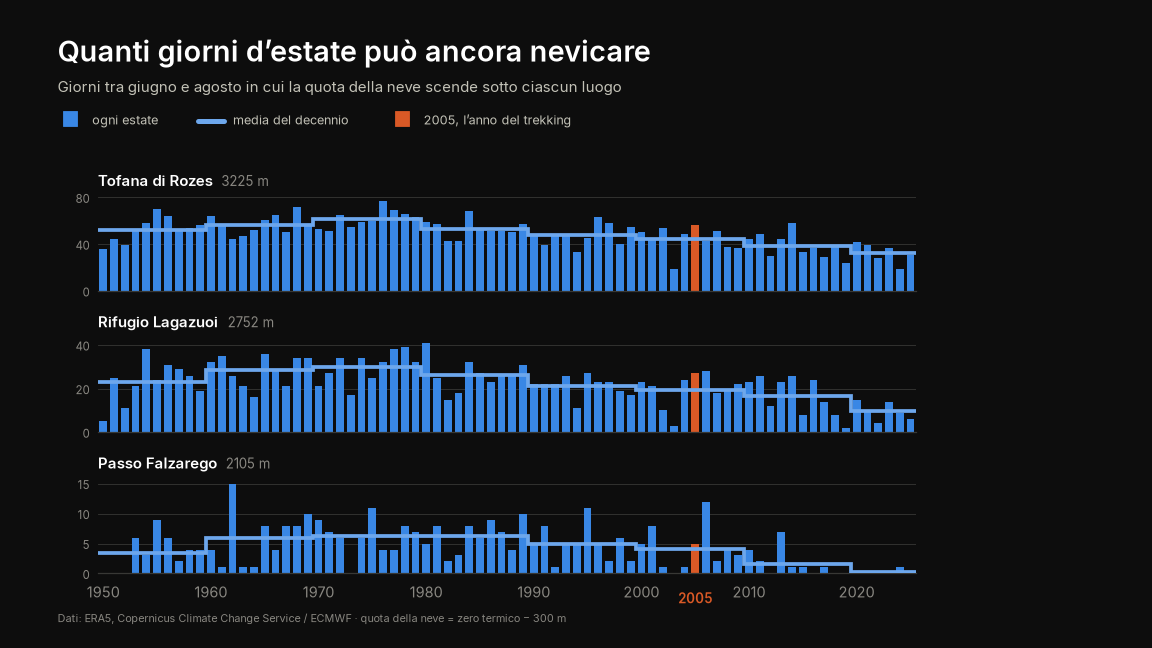

In [7]:
import anim_giorni_neve as anim
fig, stato = anim.costruisci()
stato(anim.TEMPI["zoom"])
mostra(fig)

```bash
python scripts/zero_termico.py --trend --soglie
python scripts/zero_termico.py --da 1979 --soglie
```

## 3c. The lowest freezing level of each summer

The same data, read differently: for each summer, the lowest freezing level reached, the 5th percentile and the mean.

In [8]:
z = leggi("zero_termico_estivo.csv")
anni = [int(x["anno"]) for x in z]
righe = []
for nome, col in (("summer mean", "media_m"), ("5th percentile", "p5_m"), ("lowest", "minimo_m")):
    v = [float(x[col]) for x in z]
    b, se, t = ols(anni, v)
    righe.append((nome, f"{media(anni, v, 1970, 1979):.0f} m", f"{media(anni, v, 2020, 2025):.0f} m",
                  f"{b * 10:+.0f} m/decade", f"{t:+.1f}"))
tabella(["", "1970s", "2020-25", "trend", "t"], righe)
minimo = {int(x["anno"]): float(x["minimo_m"]) for x in z}
print(f"2005: lowest at {minimo[2005]:.0f} m, rank {sorted(minimo.values()).index(minimo[2005]) + 1}"
      f" of {len(minimo)} (1 = lowest)")

# Summer by summer: how often the freezing level dropped below the pass at least once
passo = QUOTE["Passo Falzarego"]
tabella(["decade", "summers with the freezing level below Passo Falzarego"],
        [(f"{lo}–{str(min(lo + 9, anni[-1]))[2:]}",
          f"{sum(minimo[a] < passo for a in range(lo, min(lo + 10, anni[-1] + 1)))} of {min(10, anni[-1] - lo + 1)}")
         for lo in range(1950, anni[-1] + 1, 10)])
print(f"last summer: {max(a for a in minimo if minimo[a] < passo)}"
      f" ({minimo[max(a for a in minimo if minimo[a] < passo)]:.0f} m)")

|  | 1970s | 2020-25 | trend | t |
|---|---|---|---|---|
| summer mean | 3349 m | 3790 m | +43 m/decade | +6.0 |
| 5th percentile | 2439 m | 2980 m | +46 m/decade | +3.8 |
| lowest | 2003 m | 2555 m | +61 m/decade | +3.9 |

2005: lowest at 1661 m, rank 7 of 76 (1 = lowest)


| decade | summers with the freezing level below Passo Falzarego |
|---|---|
| 1950–59 | 6 of 10 |
| 1960–69 | 5 of 10 |
| 1970–79 | 7 of 10 |
| 1980–89 | 9 of 10 |
| 1990–99 | 8 of 10 |
| 2000–09 | 3 of 10 |
| 2010–19 | 0 of 10 |
| 2020–25 | 0 of 6 |

last summer: 2006 (1558 m)


In the 1970s the lowest summer freezing level averaged 2003 m, below **Passo Falzarego** (2105 m). In 2020-2025 it averaged 2555 m, above the pass. The 5th percentile rose from 2439 to 2980 m, above **Rifugio Lagazuoi** (2752 m). On **Tofana di Rozes** (3225 m) the freezing level still drops below the summit every summer.

In 2005 the lowest freezing level was 1661 m, the 7th lowest of 76 summers. Until the 1990s it dropped below the pass in 5 to 9 summers out of 10; in 2000-2009 three times, including 2005 and 2006 (1558 m). It has not happened since 2007.

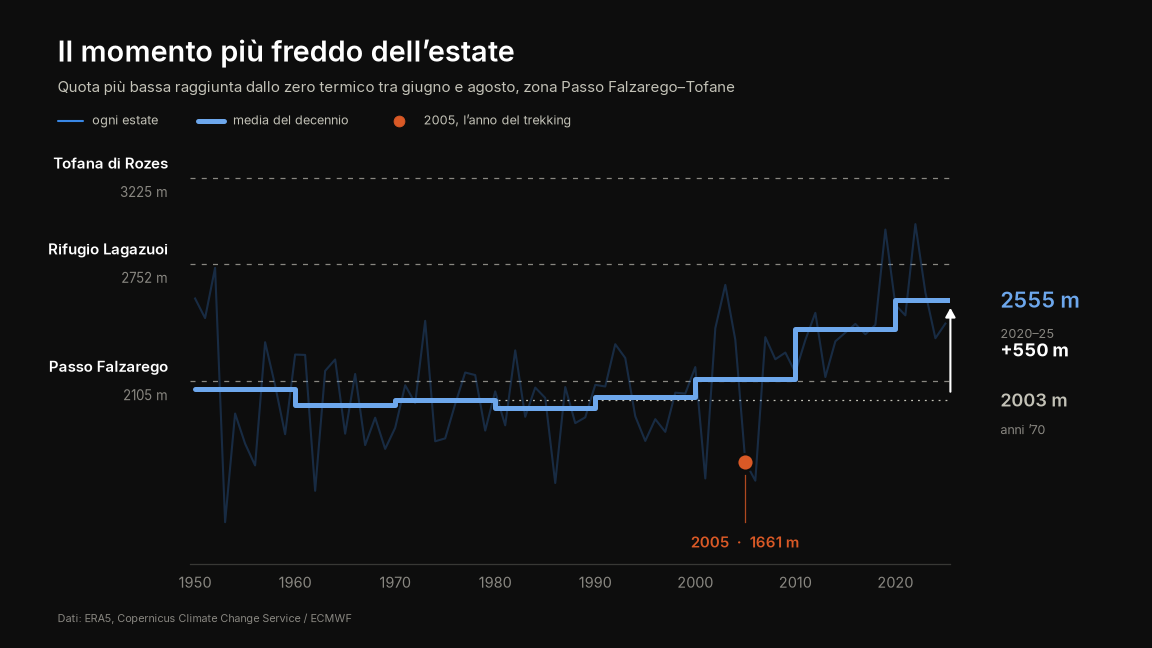

In [9]:
import anim_zero_termico as anim
fig, stato = anim.costruisci()
stato(anim.TEMPI["fine"])
mostra(fig)

```bash
python scripts/zero_termico.py --serie --csv
```

## 4. Summer temperature trends at the ARPAV stations

Monthly bulletins 1994-2024 of the ARPAV network in Veneto, from sea level to 2235 m. A summer counts only if June, July and August each have at most 5 missing days, and a station needs at least 20 complete summers. Each station on its own series:

In [10]:
s = leggi("trend_estivo_stazioni_arpav.csv")
tr = [float(x["trend_c_per_decennio"]) for x in s]
q1, q2, q3 = statistics.quantiles(tr, n=4)
tabella(["", ""], [
    ("stations with a positive summer trend", f"{sum(t > 0 for t in tr)} of {len(tr)}"),
    ("of which significant (\\|t\\| > 2)", sum(t > 0 and abs(float(x["t"])) > 2 for t, x in zip(tr, s))),
    ("network median", f"{statistics.median(tr):+.2f} °C/decade"),
    ("quartiles / range", f"{q1:+.2f} / {q3:+.2f} · {min(tr):+.2f} to {max(tr):+.2f}"),
])

|  |  |
|---|---|
| stations with a positive summer trend | 158 of 158 |
| of which significant (\|t\| > 2) | 150 |
| network median | +0.71 °C/decade |
| quartiles / range | +0.63 / +0.80 · +0.23 to +1.09 |

No station in Veneto shows summer cooling, at any altitude. The same analysis with all stations on a common window ending in 2024:

In [11]:
# How much the starting year matters: the same analysis on windows that all end
# in 2024. Needs the ARPAV csv files, and extracts them if they are missing.
import zipfile
from parse_arpav import CSV_DIR
if not CSV_DIR.exists():
    zipfile.ZipFile(RADICE / "data/arpav/trend_variabili_meteorologiche.zip").extractall(CSV_DIR)
import edw_arpav

righe = []
for da in (1994, 1998, 2001, 2003, 2004, 2005, 2006, 2008):
    st = edw_arpav.stazioni((da, 2024))
    t = [x["trend"] for x in st]
    righe.append((f"{da}–2024", len(st), f"{sum(v > 0 for v in t)} of {len(t)}",
                  f"{statistics.median(t):+.2f}", f"{min(t):+.2f}"))
tabella(["window", "stations", "positive trend", "median, °C/decade", "lowest"], righe)

| window | stations | positive trend | median, °C/decade | lowest |
|---|---|---|---|---|
| 1994–2024 | 116 | 116 of 116 | +0.72 | +0.47 |
| 1998–2024 | 133 | 133 of 133 | +0.66 | +0.32 |
| 2001–2024 | 144 | 144 of 144 | +0.67 | +0.19 |
| 2003–2024 | 151 | 151 of 151 | +0.67 | +0.20 |
| 2004–2024 | 154 | 154 of 154 | +1.05 | +0.65 |
| 2005–2024 | 158 | 158 of 158 | +1.05 | +0.64 |
| 2006–2024 | 158 | 158 of 158 | +1.00 | +0.55 |
| 2008–2024 | 161 | 161 of 161 | +0.96 | +0.34 |

Starting anywhere between 2004 and 2008, the median trend is about +1 °C per decade; windows that include the warm summers of 1998-2003 give about +0.7 °C per decade. The figure shows the 2005-2024 window.

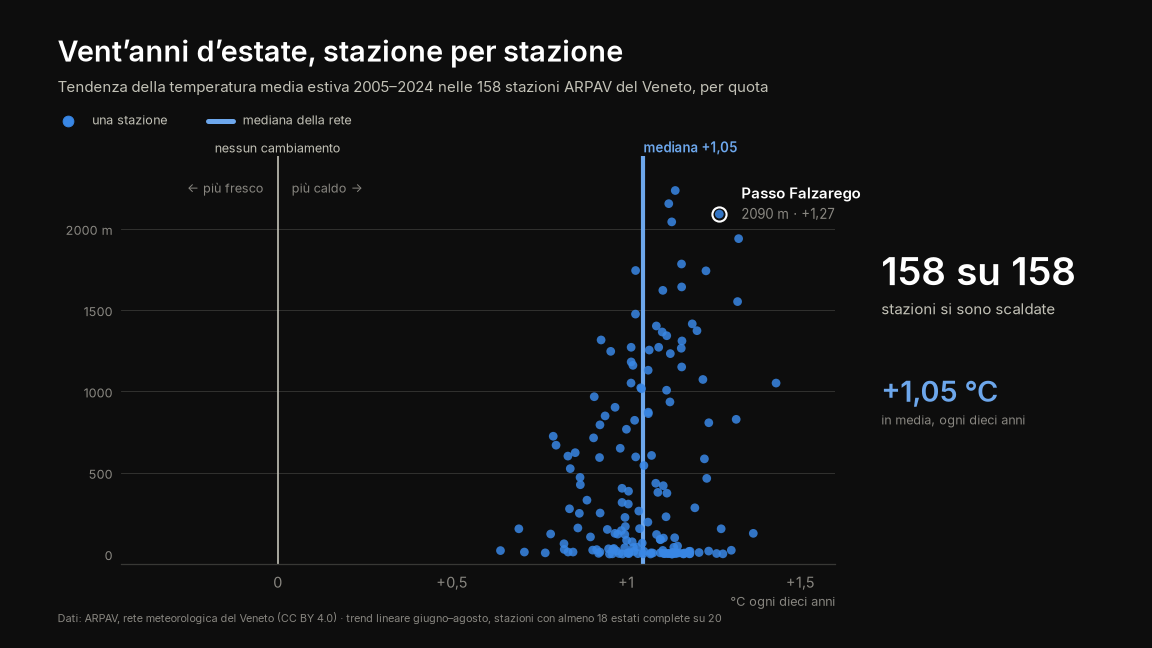

In [12]:
import anim_stazioni_arpav as anim
fig, stato = anim.costruisci()
stato(anim.TEMPI["fine"])
mostra(fig)

```bash
python scripts/edw_arpav.py --finestra 2005 2024 --csv
python scripts/anim_stazioni_arpav.py
```

## 5. Literature

- **Alpine snow**: Matiu, M., et al.: Observed snow depth trends in the European Alps: 1971 to 2019, The Cryosphere, 15, 1343-1382, 2021, doi:10.5194/tc-15-1343-2021. Over 2000 stations in six countries: mean seasonal snow depth (November-May) −8.4% per decade, maximum seasonal snow depth −5.6% per decade, snow cover duration −5.6% per decade.
- **Glaciers of the Dolomites**: Securo, A., Del Gobbo, C., Baccolo, G., Barbante, C., Citterio, M., De Blasi, F., Marcer, M., Valt, M., and Colucci, R. R.: The glaciers of the Dolomites: the last 40 years of melting, The Cryosphere, 19, 1335-1352, 2025, doi:10.5194/tc-19-1335-2025. Twelve glaciers, from the 1980s to 2023: total area from 4.11 to 1.81 km² (−56%); in 2010-2023 alone the area decreased by 0.88 km², a relative reduction of 33%. Mean surface lowering 28.7 ± 2.6 m, geodetic mass balance −0.64 ± 0.06 m w.e. per year. Fradusta lost 89% of its area, and Marmolada alone accounts for 66% of the volume loss. The surveyed glaciers include Marmolada, Sorapiss, Antelao and Cristallo, visible from the summit of Tofana di Rozes.

## 6. Data limitations

1. **ERA5 resolution.** The grid spacing is about 31 km, and in the Dolomites the model orography is smoothed by more than 1000 m. Open-Meteo adjusts temperature to the real altitude, but not precipitation: the snow indices for Passo Falzarego and Rifugio Giussani are identical because they come from the same grid cell. The freezing level varies on larger scales and is well represented at this resolution.
2. **Elevation-dependent warming.** The ARPAV network cannot measure it: 21 stations above 1250 m against 102 below 500 m, and none with a usable series above 2235 m.
3. **ARPAV monthly values.** A monthly mean is published even when only a few days were measured. Each file includes a table of missing days, used here to discard months with more than 5 missing days.
4. **ERA5-Land against ARPAV** (1994-2024, summer months), bias ERA5 minus observed:

   | station | Jun | Jul | Aug |
   |---|---:|---:|---:|
   | Cortina Gilardon 1271 m | +0.2 | +0.3 | +0.4 |
   | Passo Falzarego 2090 m | −0.5 | −0.5 | −0.7 |
   | Faloria 2235 m | −0.8 | −1.0 | −1.1 |

   The summer bias is small and stable.
5. **ARPAV period.** The series start in 1994 and do not include 2025.

## 7. Reproducibility

```bash
conda activate dolomite-change

# ARPAV stations (open data CC BY 4.0, already in data/arpav/)
python scripts/parse_arpav.py --station Passo_Falzarego --list
python scripts/parse_arpav.py --station Passo_Falzarego \
    --param "media delle medie" --anomaly 2005 --months 6 7 8

# Dating the 2005 episode
python scripts/fetch_openmeteo.py hunt --year 2005 --poi Passo_Falzarego --model era5

# Long series 1950-2025 and trends
python scripts/analisi_neve_estiva.py --poi Passo_Falzarego --csv

# Freezing level: days with possible snow by altitude, yearly series, lowest value (3b, 3c)
python scripts/zero_termico.py --soglie --serie --csv

# Summer trend of all ARPAV stations (section 4)
python scripts/edw_arpav.py --csv
python scripts/edw_arpav.py --finestra 2005 2024 --csv

# Reanalysis against station
python scripts/fetch_openmeteo.py validate --poi Passo_Falzarego
```

Sources: ARPAV, *Principali variabili meteorologiche 1994-2024*, open data CC BY 4.0. ERA5 and ERA5-Land, Copernicus Climate Change Service (C3S)/ECMWF, via the Open-Meteo archive. The ERA5 pressure-level fields for the freezing level (1c, 3b, 3c) are downloaded from the Climate Data Store with `scripts/download_era5.py` and stored in `data/era5/`.